# 1. `Linkerror event interval expired` (switch_module, error)

In [1]:
from common import *

shape, log = show(1)

log shape 110: switch_module | error | Linkerror event interval expired
80,895 logs (19.7%) from 16 nodes, 2004-01-14 16:43:12 to 2005-05-18 16:40:59
log 341909 at 2004-03-18 13:08:55: 272454 Interconnect-0N02 switch_module error 1079615335 1 Linkerror event interval expired


#### Even though state='error', this doesn't look dangerous on its own. 
But I want to see what preceded it on Interconnect-0N02.
Let's see what this switch logged in the day before

In [2]:
print(logs.node_timeline(log.node, log.ts - timedelta(days=1), log.ts))

[TimelineEntry(component='switch_module', state='error', template='Linkerror event interval expired', log_shape_id=110, first_ts='2004-03-18 13:08:37', last_ts='2004-03-18 13:08:55', count=13)]


#### Looks like this node gets a lot of these logs, but nothing else is happening.
Is this just constant noise? How does it distribute over time?
- Logs of this shape on this switch per hour, over the 31 days before:

In [3]:
month = (log.ts - timedelta(days=31), log.ts)
on_switch = per_hour(*month, node=log.node, log_shape_id=shape.log_shape_id)
print(f"{len(on_switch)} of the {31 * 24 + 1} hours have this log on this switch. The 20 busiest:")
display(sorted(on_switch.astype(int).nlargest(20).items()))

35 of the 745 hours have this log on this switch. The 20 busiest:


[('2004-02-19 18', 16),
 ('2004-02-20 03', 21),
 ('2004-02-24 07', 14),
 ('2004-02-24 13', 69),
 ('2004-02-24 18', 72),
 ('2004-02-25 19', 158),
 ('2004-02-25 20', 71),
 ('2004-02-26 15', 168),
 ('2004-02-26 17', 254),
 ('2004-02-27 10', 157),
 ('2004-02-27 11', 48),
 ('2004-02-27 14', 197),
 ('2004-02-27 15', 29),
 ('2004-02-27 17', 83),
 ('2004-03-01 05', 81),
 ('2004-03-05 06', 216),
 ('2004-03-11 14', 148),
 ('2004-03-11 23', 134),
 ('2004-03-12 05', 76),
 ('2004-03-14 07', 17)]

#### We have separated peaks of these logs, so it doesn't look like constant noise, but rather it arrives in bursts.
A burst says something happened, not that something broke. Two very different stories could produce this scenario:
- The switch is the cause: a bad cable or port on 0N02 keeps flapping.
- The switch is the witness: compute nodes attached to it rebooted or crashed.
When a node goes down, its end of the link drops, and the switch logs link errors for it.

Let's look at everything the cluster logged, from an hour before our log.

In [4]:
display(shapes_between(log.ts - hour, log.ts))

,component,state,template,n_logs,n_sources,first,last
0,switch_module,error,Linkerror event interval expired,176,7,2004-03-18 12:28:53,2004-03-18 13:08:55
1,gige,temperature,normal,4,2,2004-03-18 12:32:07,2004-03-18 13:07:07
2,gige,temperature,warning,3,2,2004-03-18 12:37:07,2004-03-18 12:52:07
3,node,status,not responding,93,93,2004-03-18 13:08:12,2004-03-18 13:08:55
4,clusterfilesystem,clusterfilesystem.no_server,ClusterFileSystem: There is no server for ServerFileSystem domain storage<N>,56,1,2004-03-18 13:08:21,2004-03-18 13:08:38
5,domain,status,inconsistent nodesets <NODE> <HEX> <ok>,2,2,2004-03-18 13:08:30,2004-03-18 13:08:30
6,node,status,configured out,58,58,2004-03-18 13:08:30,2004-03-18 13:08:31
7,partition,status,blocked,1,1,2004-03-18 13:08:30,2004-03-18 13:08:30


Two things to notice here:
- The Linkerror appears in 7 different switches.
- Some nodes arent responding in this time range. But the Linkerror messages around the cluster started earlier.
#### However, from re-examining this node's timeline (see a few cells above), we know that this message started on OUR component at 2004-03-18 13:08:37, while we see in the last cell that nodes started not responding at 2004-03-18 13:08:12.

Let's see the order at which things are happening

<Axes: xlabel='Time', ylabel='Log count'>

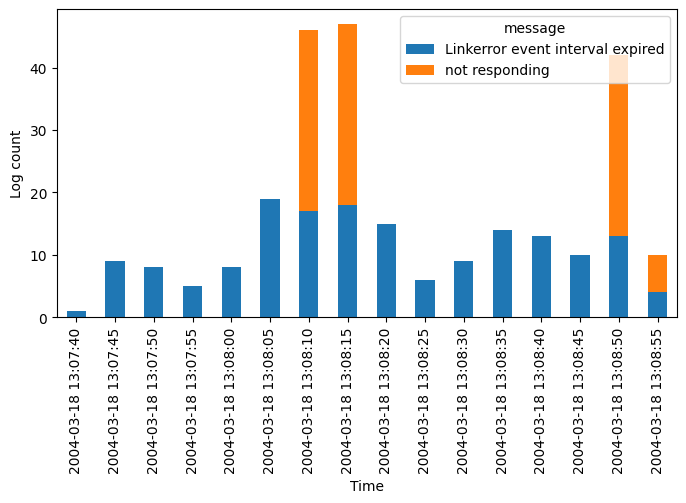

In [5]:
ten_minutes = pd.DataFrame([asdict(l) for l in logs.search(log.ts - 10 * minute, log.ts)])
ten_minutes = ten_minutes[ten_minutes["message"].isin(["Linkerror event interval expired", "not responding"])]
(
    ten_minutes.groupby([pd.Grouper(key="ts", freq="5s"), "message"])
    .size()
    .unstack(fill_value=0)
    .plot(kind="bar", stacked=True, figsize=(8, 4), xlabel="Time", ylabel="Log count")
)

Interleaved messages of `not responding` and `Linkerror event interval expired`.

By the `n_sources` high number for both message types, looks like a wide-spread problem with the nodes, or maybe we are undergoing cluster maintanance.

# Verdict: this log is in the first minute of an outage of most of the cluster. Critical, but the incident is the outage and this line is a symptom of it.